In [2]:
import pandas as pd
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt


In [7]:
df = pd.read_csv(r"C:\Users\Danie\Documents\DA\Proyectos\eCommerce\eCommerce-dataset.csv")


In [8]:
df.head(10)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
5,35.0,Male,Japan,Tokyo,3.5,6,21.9,6.9,74.4,0.0,...,16.0,8.0,2.0,14.3,11.2,2.0,1995.43,2418.0,1,Q1
6,56.0,Male,Germany,Berlin,1.9,24,46.4,13.9,36.2,5.0,...,35.5,4.0,6.0,68.8,42.9,5.0,3003.57,2657.0,0,Q1
7,47.0,Female,USA,Houston,1.6,14,24.1,8.3,59.9,2.0,...,5.5,5.0,NaN,30.1,7.6,2.0,1394.04,2274.0,0,Q4
8,32.0,Male,Canada,Calgary,1.3,14,NaN,7.4,66.5,4.0,...,19.0,2.0,0.0,0.0,18.7,2.0,537.21,534.0,0,Q1
9,44.0,Male,USA,New York,3.6,13,31.3,5.4,62.6,3.0,...,11.7,2.0,1.0,13.5,21.5,2.0,807.84,977.0,0,Q2


In [11]:
df.dtypes

Age                              float64
Gender                               str
Country                              str
City                                 str
Membership_Years                 float64
Login_Frequency                    int64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
Signup_Quarter  

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null  float64
 1

In [13]:
df.isnull().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [14]:
for col in df.columns:
    if df[col].isnull().sum() > 0:

        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())

        else:
            df[col] = df[col].fillna(df[col].mode()[0])

In [15]:
df.isnull().sum()

Age                              0
Gender                           0
Country                          0
City                             0
Membership_Years                 0
Login_Frequency                  0
Session_Duration_Avg             0
Pages_Per_Session                0
Cart_Abandonment_Rate            0
Wishlist_Items                   0
Total_Purchases                  0
Average_Order_Value              0
Days_Since_Last_Purchase         0
Discount_Usage_Rate              0
Returns_Rate                     0
Email_Open_Rate                  0
Customer_Service_Calls           0
Product_Reviews_Written          0
Social_Media_Engagement_Score    0
Mobile_App_Usage                 0
Payment_Method_Diversity         0
Lifetime_Value                   0
Credit_Balance                   0
Churned                          0
Signup_Quarter                   0
dtype: int64

In [16]:
df['Churned'].value_counts()


Churned
0    35550
1    14450
Name: count, dtype: int64

In [17]:
df['Churned'].value_counts(normalize=True) * 100

Churned
0    71.1
1    28.9
Name: proportion, dtype: float64

In [18]:
df.groupby('Churned')['Login_Frequency'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Churned,,,,,
0,35550,12.642391,12.0,0,46
1,14450,9.120830,8.0,0,43


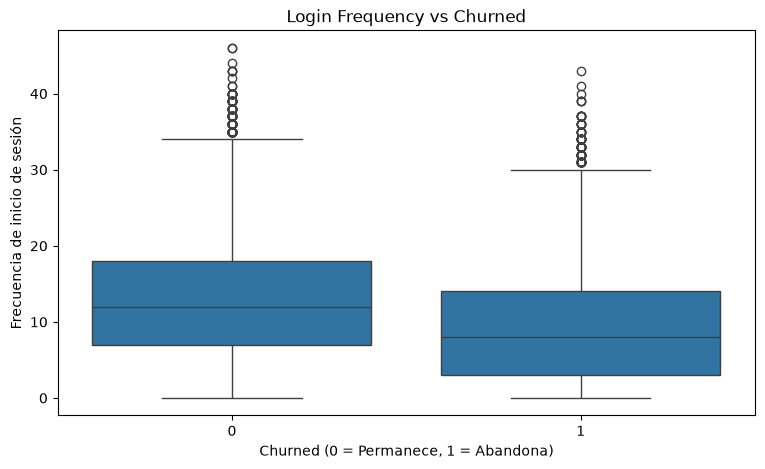

In [19]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Churned',
    y='Login_Frequency'
)

plt.title('Login Frequency vs Churned')
plt.xlabel('Churned (0 = Permanece, 1 = Abandona)')
plt.ylabel('Frecuencia de inicio de sesión')

plt.show()

In [20]:
df['Login_Group'] = pd.cut(
    df['Login_Frequency'],
    bins=4,
    labels=['Baja', 'Media-baja', 'Media-alta', 'Alta']
)

churn_by_login = df.groupby(
    'Login_Group',
    observed=True
)['Churned'].mean() * 100

churn_by_login

Login_Group
Baja          35.998334
Media-baja    21.673449
Media-alta    17.789757
Alta          10.619469
Name: Churned, dtype: float64

In [21]:
#antigüedad del cliente vs. abandono

df.groupby('Churned')['Membership_Years'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Churned,,,,,
0,35550,2.984828,2.5,0.1,10.0
1,14450,2.981996,2.5,0.1,10.0


In [22]:
df['Membership_Group'] = pd.cut(
    df['Membership_Years'],
    bins=[0, 1, 3, 5, 10],
    labels=['Nuevo', 'Intermedio', 'Establecido', 'Antiguo'],
    include_lowest=True
)

churn_by_membership = df.groupby(
    'Membership_Group',
    observed=True
)['Churned'].agg(['count', 'mean'])

churn_by_membership['churn_rate'] = (
    churn_by_membership['mean'] * 100
)

churn_by_membership

,count,mean,churn_rate
Membership_Group,,,
Nuevo,7848,0.286442,28.644241
Intermedio,22317,0.289689,28.968947
Establecido,12282,0.290832,29.083211
Antiguo,7553,0.286641,28.664107


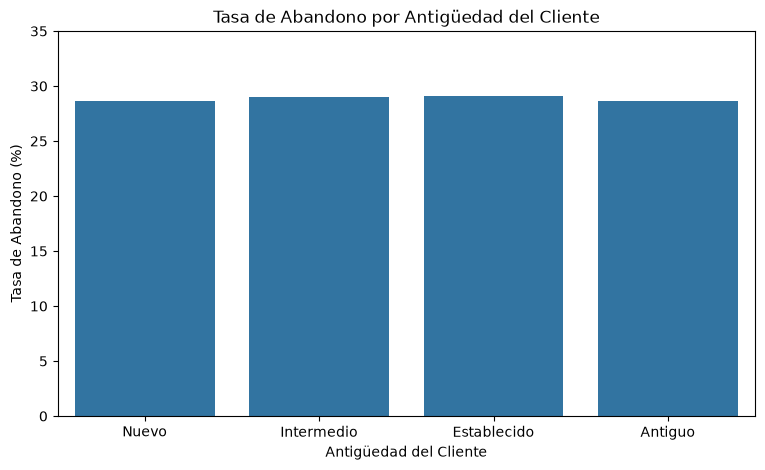

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Membership_Group',
    y='Churned',
    estimator=lambda x: x.mean() * 100,
    errorbar=None
)

plt.title('Tasa de Abandono por Antigüedad del Cliente')
plt.xlabel('Antigüedad del Cliente')
plt.ylabel('Tasa de Abandono (%)')

plt.ylim(0, 35)

plt.show()

In [23]:
##La antigüedad del cliente no parece estar relacionada de manera importante con el abandono. Los clientes nuevos y antiguos presentan prácticamente el mismo comportamiento.